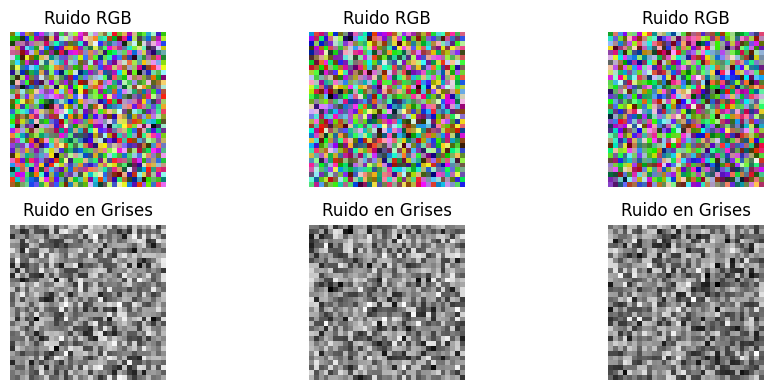

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Capa personalizada (sin pesos entrenables)
class CapaEscalaGrises(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(CapaEscalaGrises, self).__init__(**kwargs)

    def call(self, inputs):
        pesos_rgb = tf.constant([0.2989, 0.5870, 0.1140], dtype=inputs.dtype)
        grises = tf.reduce_sum(inputs * pesos_rgb, axis=-1, keepdims=True)
        return grises

# 2. Pruebas con ruido RGB aleatorio
# Tamaño: 3 imágenes, 32x32 píxeles, 3 canales (Color)
imagenes_prueba = tf.random.uniform(shape=(3, 32, 32, 3), minval=0.0, maxval=1.0)

capa_grises = CapaEscalaGrises()
imagenes_transformadas = capa_grises(imagenes_prueba)

# 3. Visualización
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imagenes_prueba[i]) # Se verá como estática de colores
    plt.title("Ruido RGB")
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(tf.squeeze(imagenes_transformadas[i]), cmap="gray") # Se verá como estática blanco y negro
    plt.title("Ruido en Grises")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip install --upgrade wandb

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc



🔗 ENLACE WANDB PARA REPORTE (Prob 2A): https://wandb.ai/rosi-s-s-09-buap/Tarea3-RNA/runs/gkcitu0r



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


loss,▃▂▂▁▁▄█▁▁▁▁▁▁▅▅▁▁▁▁▁▁▁▁▂▃▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁
loss,0.0005



🔗 ENLACE WANDB PARA REPORTE (Prob 2B): https://wandb.ai/rosi-s-s-09-buap/Tarea3-RNA/runs/j0o4vrj2



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


loss,█▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,0.00019


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


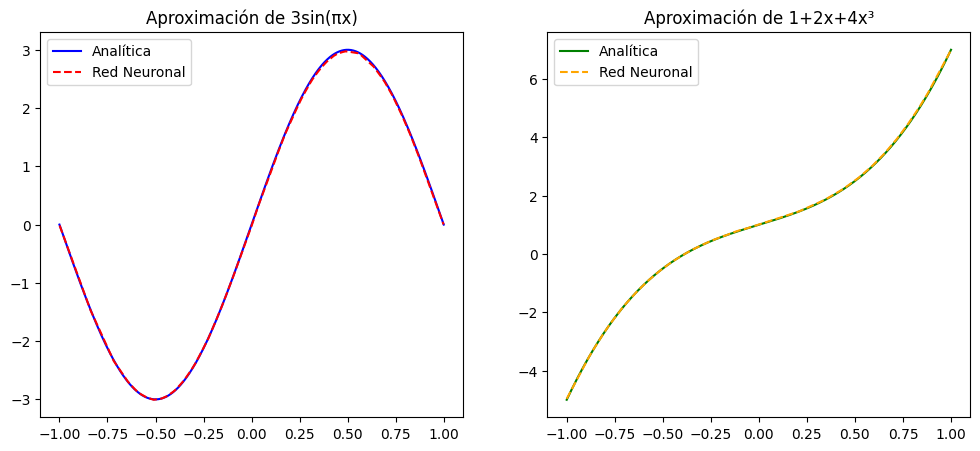

In [4]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import wandb

wandb.login(key="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")

# Datos de entrenamiento en el intervalo [-1, 1]
x_train = np.linspace(-1, 1, 1000).reshape(-1, 1)
y_a = 3 * np.sin(np.pi * x_train)
y_b = 1 + 2 * x_train + 4 * x_train**3

# PROBLEMA 2A: 3sin(πx)
run_a = wandb.init(project="Tarea3-RNA", name="prob2a-seno")
print(f"\n🔗 ENLACE WANDB PARA REPORTE (Prob 2A): {run_a.url}\n")

modelo_a = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])
modelo_a.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
historial_a = modelo_a.fit(x_train, y_a, epochs=150, verbose=0)

# Registro manual en WandB
for p in historial_a.history['loss']:
    wandb.log({"loss": p})
wandb.finish()

# PROBLEMA 2B: 1+2x+4x^3
run_b = wandb.init(project="Tarea3-RNA", name="prob2b-polinomio")
print(f"\n🔗 ENLACE WANDB PARA REPORTE (Prob 2B): {run_b.url}\n")

modelo_b = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])
modelo_b.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
historial_b = modelo_b.fit(x_train, y_b, epochs=150, verbose=0)

# Registro manual en WandB
for p in historial_b.history['loss']:
    wandb.log({"loss": p})
wandb.finish()

# VISUALIZACIÓN
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(x_train, y_a, label="Analítica", color='blue')
plt.plot(x_train, modelo_a.predict(x_train), label="Red Neuronal", color='red', linestyle='dashed')
plt.title("Aproximación de 3sin(πx)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x_train, y_b, label="Analítica", color='green')
plt.plot(x_train, modelo_b.predict(x_train), label="Red Neuronal", color='orange', linestyle='dashed')
plt.title("Aproximación de 1+2x+4x³")
plt.legend()
plt.show()

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc



🔗 ENLACE WANDB PARA REPORTE (Prob 3): https://wandb.ai/rosi-s-s-09-buap/Tarea3-RNA/runs/mnn0dhm6

Entrenando capa polinomial para cos(2x)...


/tmp/ipykernel_12369/2222260161.py:12: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(CapaPolinomio, self).__init__(**kwargs)


loss,▁▁▂▁▂▄▃▃▃▃▂▄█▂▃▃▂▂▆▃▂▃▃▄▃▅▂▃▄▅▁▂▅▃▇▃▃▄▆▂
loss,0.00206


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Coeficientes aprendidos: a0=0.9425, a1=-0.0055, a2=-1.4828, a3=-0.0038


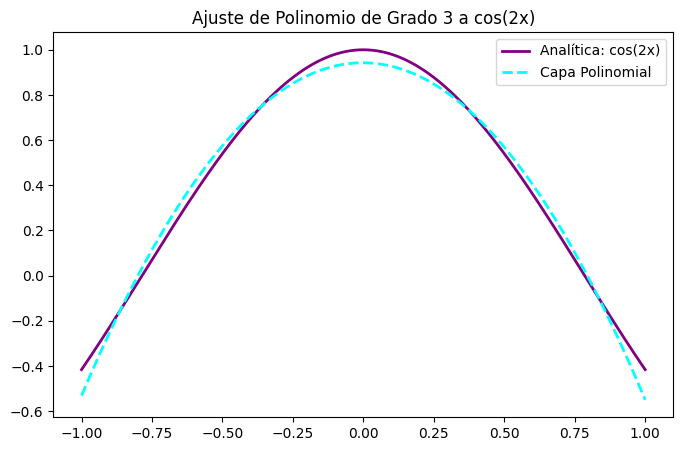

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import wandb

# 1. Insertar API Key de WandB
wandb.login(key="API KEY")

# PROBLEMA 3: Capa Polinomial Entrenable
class CapaPolinomio(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(CapaPolinomio, self).__init__(**kwargs)

    def build(self, input_shape):
        # Declarar los 4 coeficientes como pesos entrenables (trainable=True)
        self.a0 = self.add_weight(shape=(1,), initializer='zeros', trainable=True, name='a0')
        self.a1 = self.add_weight(shape=(1,), initializer='random_normal', trainable=True, name='a1')
        self.a2 = self.add_weight(shape=(1,), initializer='random_normal', trainable=True, name='a2')
        self.a3 = self.add_weight(shape=(1,), initializer='random_normal', trainable=True, name='a3')

    def call(self, inputs):
        # f(x) = a0 + a1*x + a2*x^2 + a3*x^3
        return self.a0 + self.a1 * inputs + self.a2 * tf.math.pow(inputs, 2) + self.a3 * tf.math.pow(inputs, 3)

# 2. Generar datos en el intervalo [-1, 1]
x_train = np.linspace(-1, 1, 1000).reshape(-1, 1)
y_train = np.cos(2 * x_train) # Ajustar a f(x) = cos(2x)

# 3. Iniciar WandB
run_prob3 = wandb.init(project="Tarea3-RNA", name="prob3-polinomio")
print(f"\n🔗 ENLACE WANDB PARA REPORTE (Prob 3): {run_prob3.url}\n")

# 4. Construir y entrenar el modelo
modelo_poli = tf.keras.Sequential([
    CapaPolinomio(input_shape=(1,))
])

# Usamos un learning rate de 0.05 para que los coeficientes converjan más rápido
modelo_poli.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.05), loss='mse')

print("Entrenando capa polinomial para cos(2x)...")
historial_poli = modelo_poli.fit(x_train, y_train, epochs=250, verbose=0)

# Registro manual en WandB
for p in historial_poli.history['loss']:
    wandb.log({"loss": p})
wandb.finish()

# 5. Resultados y Visualización
y_pred = modelo_poli.predict(x_train)

# Extraer los pesos finales aprendidos por la red
pesos = modelo_poli.layers[0].get_weights()
print(f"Coeficientes aprendidos: a0={pesos[0][0]:.4f}, a1={pesos[1][0]:.4f}, a2={pesos[2][0]:.4f}, a3={pesos[3][0]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(x_train, y_train, label="Analítica: cos(2x)", color='purple', linewidth=2)
plt.plot(x_train, y_pred, label="Capa Polinomial", color='cyan', linestyle='dashed', linewidth=2)
plt.title("Ajuste de Polinomio de Grado 3 a cos(2x)")
plt.legend()
plt.show()

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rosi-s-s-09 (rosi-s-s-09-buap) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



🔗 ENLACE WANDB PARA REPORTE (Prob 4A): https://wandb.ai/rosi-s-s-09-buap/Tarea3-RNA/runs/b1pppl1p

Entrenando PINN para el Problema 4A...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,0.01221



🔗 ENLACE WANDB PARA REPORTE (Prob 4B): https://wandb.ai/rosi-s-s-09-buap/Tarea3-RNA/runs/o3zd5u7x

Entrenando PINN para el Problema 4B...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,0.00011


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


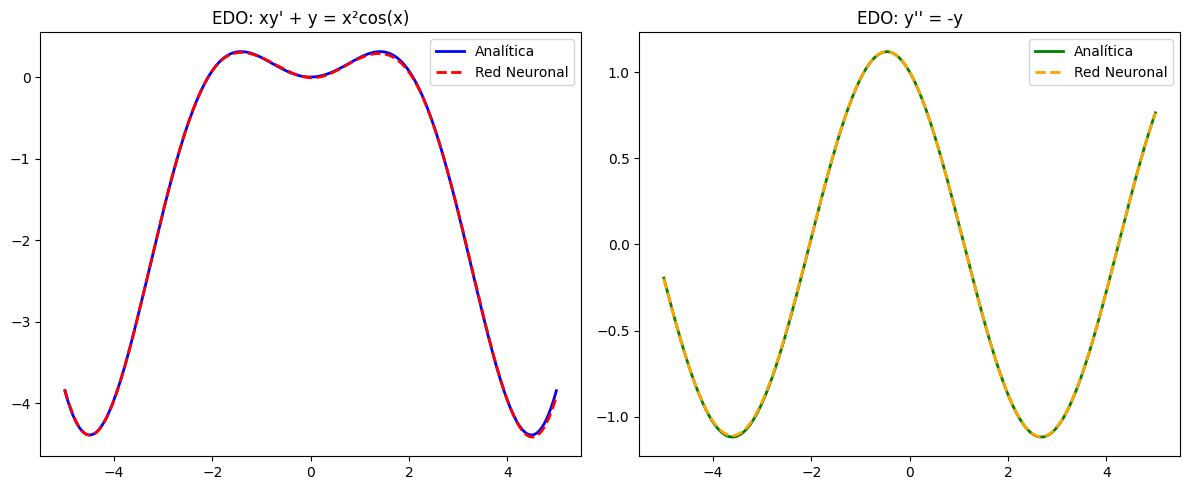

In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import wandb

# 1. API KEY
wandb.login(key="API KEY")

# Generar tensores de entrenamiento en el intervalo [-5, 5]
x_train = np.linspace(-5, 5, 400).reshape(-1, 1)
x_tensor = tf.convert_to_tensor(x_train, dtype=tf.float32)
x_0 = tf.constant([[0.0]], dtype=tf.float32)

# PROBLEMA 4A: xy' + y = x^2 cos(x), y(0) = 0
run_4a = wandb.init(project="Tarea3-RNA", name="prob4a-EDO1")
print(f"\n🔗 ENLACE WANDB PARA REPORTE (Prob 4A): {run_4a.url}\n")

# Solución analítica 4A: y(x) = x*sin(x) + 2*cos(x) - 2*sin(x)/x
y_exact_a = x_train * np.sin(x_train) + 2 * np.cos(x_train) - 2 * np.sinc(x_train / np.pi)

modelo_4a = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='tanh', input_shape=(1,)),
    tf.keras.layers.Dense(32, activation='tanh'),
    tf.keras.layers.Dense(32, activation='tanh'),
    tf.keras.layers.Dense(1)
])
opt_4a = tf.keras.optimizers.Adam(learning_rate=0.01)

print("Entrenando PINN para el Problema 4A...")
for epoch in range(1500):
    with tf.GradientTape() as tape_model:
        with tf.GradientTape() as tape_x:
            tape_x.watch(x_tensor)
            y_pred = modelo_4a(x_tensor)
        dy_dx = tape_x.gradient(y_pred, x_tensor)

        edo_loss = tf.reduce_mean(tf.square(x_tensor * dy_dx + y_pred - (x_tensor**2 * tf.cos(x_tensor))))
        bc_loss = tf.square(modelo_4a(x_0) - 0.0)

        loss = edo_loss + 10.0 * bc_loss

    grads = tape_model.gradient(loss, modelo_4a.trainable_variables)
    opt_4a.apply_gradients(zip(grads, modelo_4a.trainable_variables))

    if epoch % 50 == 0:
        wandb.log({"loss": loss.numpy()[0][0]})

wandb.finish()

# PROBLEMA 4B: y'' = -y, y(0)=1, y'(0)=-0.5
run_4b = wandb.init(project="Tarea3-RNA", name="prob4b-EDO2")
print(f"\n🔗 ENLACE WANDB PARA REPORTE (Prob 4B): {run_4b.url}\n")

# Solución analítica 4B: y(x) = cos(x) - 0.5*sin(x) (Corregido aquí)
y_exact_b = np.cos(x_train) - 0.5 * np.sin(x_train)

modelo_4b = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='tanh', input_shape=(1,)),
    tf.keras.layers.Dense(32, activation='tanh'),
    tf.keras.layers.Dense(32, activation='tanh'),
    tf.keras.layers.Dense(1)
])
opt_4b = tf.keras.optimizers.Adam(learning_rate=0.01)

print("Entrenando PINN para el Problema 4B...")
for epoch in range(1500):
    with tf.GradientTape() as tape_model:
        with tf.GradientTape() as tape2:
            tape2.watch(x_tensor)
            with tf.GradientTape() as tape1:
                tape1.watch(x_tensor)
                y_pred = modelo_4b(x_tensor)
            dy_dx = tape1.gradient(y_pred, x_tensor)
        d2y_dx2 = tape2.gradient(dy_dx, x_tensor)

        edo_loss = tf.reduce_mean(tf.square(d2y_dx2 + y_pred))

        with tf.GradientTape() as tape_bc:
            tape_bc.watch(x_0)
            y_0 = modelo_4b(x_0)
        dy_dx_0 = tape_bc.gradient(y_0, x_0)

        bc_loss = tf.square(y_0 - 1.0) + tf.square(dy_dx_0 - (-0.5))
        loss = edo_loss + 10.0 * bc_loss

    grads = tape_model.gradient(loss, modelo_4b.trainable_variables)
    opt_4b.apply_gradients(zip(grads, modelo_4b.trainable_variables))

    if epoch % 50 == 0:
        wandb.log({"loss": loss.numpy()[0][0]})

wandb.finish()

# GRAFICAR RESULTADOS
plt.figure(figsize=(12, 5))

# Gráfica 4A
plt.subplot(1, 2, 1)
plt.plot(x_train, y_exact_a, label="Analítica", color='blue', linewidth=2)
plt.plot(x_train, modelo_4a.predict(x_tensor), label="Red Neuronal", color='red', linestyle='dashed', linewidth=2)
plt.title("EDO: xy' + y = x²cos(x)")
plt.legend()

# Gráfica 4B
plt.subplot(1, 2, 2)
plt.plot(x_train, y_exact_b, label="Analítica", color='green', linewidth=2)
plt.plot(x_train, modelo_4b.predict(x_tensor), label="Red Neuronal", color='orange', linestyle='dashed', linewidth=2)
plt.title("EDO: y'' = -y")
plt.legend()

plt.tight_layout()
plt.show()